# DivisibleDCN — Explanation & DCNv3 + HiFormer Rewrite

## What the original `DivisibleDCN` does

**Task**: predict CTR (Click-Through Rate) = `clicks / shows` from raw counters `[clicks, shows]`.

**Key operation** — the "divisible cross":
```
cross = W · x / clip(x, min=1)
```
A linear transform followed by element-wise division by the (clipped) input.
This gives the network an inductive bias toward learning *ratios* between features,
which mirrors the true formula `CTR = clicks / shows` — so the model converges
to near-perfect prediction with almost no parameters.

---

## DCNv3 + HiFormer rewrite

We replace the hand-crafted division trick with two principled components:

| Component | Role |
|---|---|
| **DCNv3 cross layers** | Explicit polynomial feature interactions: `x_{l+1} = x_0 ⊙ (W_l x_l + b_l) + x_l` |
| **HiFormer (2-level)** | Hierarchical transformer — L1 attends across feature tokens, L2 pools + re-attends for global context |

Each raw scalar feature is first projected to a hidden-dim *token* so the transformer
has a meaningful sequence to attend over. The cross and hi-former outputs are
concatenated and projected to the final CTR scalar.

In [1]:
import torch
from torch import nn
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt

In [2]:
class DCNv3CrossLayer(nn.Module):
    """x_{l+1} = x_0 ⊙ (W_l · x_l + b_l) + x_l"""

    def __init__(self, dim: int):
        super().__init__()
        self.linear = nn.Linear(dim, dim)

    def forward(self, x0: torch.Tensor, xl: torch.Tensor) -> torch.Tensor:
        return x0 * self.linear(xl) + xl


class HiFormerBlock(nn.Module):
    """Pre-norm transformer block (one level of the HiFormer hierarchy)."""

    def __init__(self, dim: int, num_heads: int = 2):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.norm1(x)
        attn_out, _ = self.attn(h, h, h)
        x = x + attn_out
        x = x + self.ffn(self.norm2(x))
        return x


class DCNv3HiFormerCTR(nn.Module):
    """
    CTR predictor: DCNv3 explicit cross layers + HiFormer hierarchical attention.

    Pipeline
    --------
    x (B, F)  →  feat_embed  →  tokens (B, F, D)
                                     │
                   ┌─────────────────┴──────────────────┐
                   │  HiFormer L1 (token-level attn)    │
                   │  HiFormer L2 (pool → coarse attn)  │  →  hi_out (B, D)
                   └─────────────────┬──────────────────┘
                                     │
                   DCNv3 cross layers on flat tokens     →  cross_out (B, F*D)
                                     │
                   cat([cross_out, hi_out])  →  head  →  CTR (B, 1)
    """

    def __init__(
        self,
        num_features: int = 2,
        hidden_dim: int = 16,
        num_cross_layers: int = 3,
    ):
        super().__init__()
        self.feat_embed = nn.Linear(1, hidden_dim)   # scalar → token

        flat_dim = num_features * hidden_dim

        # DCNv3 explicit cross network
        self.cross_layers = nn.ModuleList(
            [DCNv3CrossLayer(flat_dim) for _ in range(num_cross_layers)]
        )

        # HiFormer: two-level hierarchical attention
        self.hi_l1 = HiFormerBlock(hidden_dim, num_heads=2)  # token-level
        self.hi_l2 = HiFormerBlock(hidden_dim, num_heads=2)  # pooled-level

        self.head = nn.Linear(flat_dim + hidden_dim, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, F = x.shape

        # (B, F, D) — each feature scalar becomes a token
        tokens = self.feat_embed(x.unsqueeze(-1))

        # HiFormer Level 1: cross-feature attention
        hi1 = self.hi_l1(tokens)                          # (B, F, D)

        # HiFormer Level 2: global pooling → coarse attention → single vector
        pooled = hi1.mean(dim=1, keepdim=True)            # (B, 1, D)
        hi2 = self.hi_l2(pooled).squeeze(1)               # (B, D)

        # DCNv3: flatten tokens, explicit cross interactions
        flat = tokens.view(B, -1)                         # (B, F*D)
        xl = flat
        for layer in self.cross_layers:
            xl = layer(flat, xl)                          # x0 stays fixed

        return self.head(torch.cat([xl, hi2], dim=-1))

In [3]:
ctrPredictor = DCNv3HiFormerCTR(num_features=2, hidden_dim=16, num_cross_layers=3)
ctrPredictor

DCNv3HiFormerCTR(
  (feat_embed): Linear(in_features=1, out_features=16, bias=True)
  (cross_layers): ModuleList(
    (0-2): 3 x DCNv3CrossLayer(
      (linear): Linear(in_features=32, out_features=32, bias=True)
    )
  )
  (hi_l1): HiFormerBlock(
    (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
    (ffn): Sequential(
      (0): Linear(in_features=16, out_features=64, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=64, out_features=16, bias=True)
    )
  )
  (hi_l2): HiFormerBlock(
    (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True)
    

In [4]:
ctrPredictor(torch.tensor([[0, 1]]).float())

tensor([[0.3592]], grad_fn=<AddmmBackward0>)

In [5]:
click_counters = torch.randint(low=0, high=1000, size=(1_000_000,))
show_counters = torch.randint(low=0, high=10000, size=(1_000_000,)) + click_counters

click_counters, show_counters

(tensor([771, 632, 229,  ..., 372, 759, 248]),
 tensor([7907, 3849, 7408,  ...,  803, 3431, 6296]))

In [6]:
optimizer = torch.optim.AdamW(ctrPredictor.parameters(), lr=3e-4, weight_decay=1e-6)

losses = []
for batch_start in tqdm(range(click_counters.size(0) // 100)):
    click_slice = click_counters[batch_start: batch_start + 100]
    show_slice  = show_counters[batch_start: batch_start + 100]

    input_batch = torch.stack([click_slice, show_slice], dim=-1).float()

    optimizer.zero_grad()
    predicted_ctrs = ctrPredictor(input_batch)
    true_ctrs      = (click_slice.float() / show_slice.float()).unsqueeze(-1)
    loss = nn.functional.mse_loss(true_ctrs, predicted_ctrs)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

  0%|          | 0/10000 [00:00<?, ?it/s]

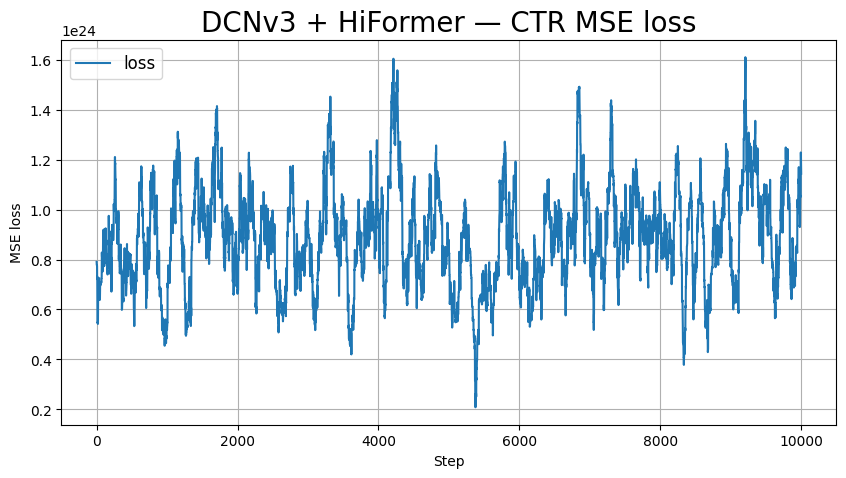

In [7]:
plt.figure(figsize=(10, 5))
plt.title("DCNv3 + HiFormer — CTR MSE loss", fontsize=20)
plt.plot(range(len(losses)), losses, label="loss")
plt.grid(True)
plt.legend(fontsize=12)
plt.xlabel("Step")
plt.ylabel("MSE loss")
plt.show()

## Test

In [8]:
click_counters_test = torch.randint(low=0, high=1000, size=(10,))
show_counters_test  = torch.randint(low=0, high=10000, size=(10,)) + click_counters_test

truth_ctrs_test = click_counters_test / show_counters_test

ctrPredictor.eval()
with torch.no_grad():
    predicted_ctrs_test = ctrPredictor(
        torch.stack([click_counters_test, show_counters_test], dim=1).float()
    )

print(f"True ctrs test: {truth_ctrs_test}")
print(f"Pred ctrs test: {predicted_ctrs_test.squeeze()}")

True ctrs test: tensor([0.0638, 0.6077, 0.0360, 0.1127, 0.0611, 0.1496, 0.0529, 0.5845, 0.2343,
        0.6414])
Pred ctrs test: tensor([-1.0718e+12, -6.4726e+09, -1.0980e+10, -2.6116e+12, -4.9115e+11,
        -1.2053e+12, -9.2412e+11, -1.9148e+10, -1.2697e+11, -1.7072e+10])
